![Banner](../../../Images/Banner/09_distributed_spatial_datas.png)

# Capstone: Soil Carbon and Cropland of Every Great Plains County

This capstone combines the whole chapter in one workflow at a scale that needs it. For each of the
225 counties of Colorado, Kansas, New Mexico and Wyoming it asks: how much of the county is
cropland, and how much organic carbon do its soils hold? Answering takes 21 billion pixels of the
2025 10 m Cropland Data Layer, 12 covariate rasters of 262 million pixels each, a machine learning
model of soil carbon predicted for every 90 m pixel, zonal statistics, and spatial statistics of
the county results. Every step runs out of core or on the GPU through `geolattice.distributed`,
the pipeline is timed stage by stage, and the results are written as GeoParquet and a
Cloud-Optimized GeoTIFF.

## Overview

### The question

Soil organic carbon (SOC) is the largest terrestrial store of carbon and a measure of soil health.
Cultivation usually lowers it, while climate and vegetation set its overall level: wetter, cooler
and greener places hold more. A county-level picture of SOC next to cropland share is the kind of
summary that carbon accounting, conservation programmes and soil health initiatives start from,
and it needs exactly the operations of this chapter.

### The pipeline

| Stage | Data | Operations (notebook) | Scale |
|---|---|---|---|
| 1. Cropland by county | 2025 CDL, 10 m | lazy read (02), lookup-table reclassification (03), zonal sums (05) | 21 billion pixels |
| 2. Training table | 570 SOC samples, 12 covariates | grid alignment (02), point extraction (05) | 570 x 12 |
| 3. Model | training table | spatial cross-validation, XGBoost on CPU and GPU (09) | 561 rows |
| 4. SOC map | 12 covariates, 90 m | chunked prediction (09), COG output (02) | 262 million pixels |
| 5. County summaries | SOC map, covariates | zonal statistics (05) | 225 zones x 4 rasters |
| 6. Spatial patterns | county table | weights, Moran's I, LISA, G* (06) | 225 counties |

### What counts as done

The final products are a county GeoParquet file with cropland areas, mean predicted SOC, climate
and terrain summaries and hot spot statistics; a SOC map as a COG; and a timing table showing
where the time went.

## The Capstone with GeoLattice

All stages use the functions of the previous notebooks: `dd.cdl`, `dd.gp_raster` and
`dd.gp_stack` (lazy readers, grids aligned), `pdist.raster.map_tiles`, `pdist.zonal_stats`,
`pdist.extract_values`, `pdist.ml.fit`, `pdist.ml.predict_raster`, `pdist.write_raster`,
`pdist.analysis.weights`, `morans_i`, `local_morans`, `getis_ord_local` and
`pdist.vector.sjoin`. The GPU is used where notebooks 03 to 09 showed it pays off (model
prediction, zonal partial sums); I/O-bound stages stay on the CPU.

### Learning objectives

1. Plan a multi-stage spatial pipeline and choose CPU or GPU per stage from earlier measurements.
2. Summarize 21 billion 10 m pixels by county out of core.
3. Build, validate and apply a soil carbon model to 262 million pixels.
4. Combine raster and vector results into a county table and analyse its spatial patterns.
5. Time each stage and write analysis-ready outputs.

### Data

| Dataset | Content |
|---|---|
| 2025 CDL | 10 m crop codes, Great Plains window of 154,776 x 137,219 pixels |
| Great Plains covariates | 12 continuous 90 m rasters, aligned to the elevation grid |
| Great Plains SOC samples | 570 points, kg m-2 |
| Great Plains counties and states | 225 counties, 4 states (EPSG:5070) |

Outputs go to `outputs/capstone/`: `counties_soc_cropland.parquet` and `soc_map_cog.tif`.

### Contents

- Setup
- Stage 1: cropland by county from the 10 m CDL
- Stage 2: the training table
- Stage 3: a validated soil carbon model
- Stage 4: the soil carbon map
- Stage 5: county summaries
- Stage 6: spatial patterns
- Outputs and the time budget
- Summary and exercises

## Setup

In [1]:
import warnings  # warning control
warnings.filterwarnings("ignore")  # hide routine library warnings
import os  # environment and CPU count
import time  # wall-clock timing
from pathlib import Path  # file paths

import matplotlib.pyplot as plt  # figures
import numpy as np  # arrays
import pandas as pd  # tables
import geopandas as gpd  # vector data
import xarray as xr  # labelled rasters

import geolattice  # GeoLattice
import geolattice.distributed as pdist  # distributed and GPU spatial computing
import dist_data as dd  # chapter helper: paths, cached downloads, timers

plt.rcParams.update({"figure.dpi": 110})  # figure resolution
pd.set_option("display.width", 140)  # wider printed tables
OUT = Path("outputs")  # results and scratch files written by this chapter
OUT.mkdir(exist_ok=True)  # create it if needed
caps = pdist.capabilities()  # engines and GPUs on this machine
print("GeoLattice", geolattice.__version__, "|", os.cpu_count(), "CPU cores |", caps["gpus"], "GPU(s)",  # versions
      f"({caps.get('gpu_memory_total', 0) / 1e9:.0f} GB)" if caps["gpus"] else "")  # GPU memory

import dask  # Dask configuration
from sklearn.cluster import KMeans  # spatial blocks for cross-validation
from sklearn.metrics import r2_score, mean_squared_error  # accuracy
CAP = OUT / "capstone"  # outputs of this notebook
CAP.mkdir(parents=True, exist_ok=True)  # create the folder
budget = {}  # seconds per stage
gpu = "gpu" if caps["gpus"] else "cpu"  # where GPU stages run
counties = dd.gp_counties()  # 225 counties
print(f"{len(counties)} counties; GPU stages run on: {gpu}")  # setup

GeoLattice 0.3.49 | 24 CPU cores | 1 GPU(s) (17 GB)


225 counties; GPU stages run on: gpu


## Stage 1: cropland by county from the 10 m CDL

A lazy three-band flag raster (all cropland, wheat, corn) is built from the CDL with lookup tables,
and `pdist.zonal_stats` sums it within each county (notebook 05). Reading and decompressing 21
billion pixels is CPU work, so this stage runs on the CPU.

In [2]:
gp = counties.total_bounds  # extent of the counties
cdl = dd.cdl(chunks={"y": 4096, "x": 4096}).sel(x=slice(gp[0], gp[2]), y=slice(gp[3], gp[1]))  # lazy 10 m window; 4096 chunks bound memory (notebook 05)
luts = {}  # lookup table per flag
for band, groups in [("crop", dd.CROP_GROUPS), ("wheat", ["Wheat"]), ("corn", ["Corn"])]:  # three flags
    lut = np.zeros(256, np.float32)  # 0 elsewhere
    for gname in groups:  # codes of the groups
        lut[dd.CDL_GROUPS[gname]] = 1.0  # 1 for them
    lut[0] = np.nan  # no data
    luts[band] = lut  # keep
flags = xr.concat([pdist.raster.map_tiles(cdl, lambda b, xp, l=l: xp.asarray(l)[b], dtype="float32", compute="cpu")  # one band per flag
                   for l in luts.values()], dim="band").assign_coords(band=list(luts))  # (3, y, x)
with dd.PeakMemory() as pm:  # watch memory
    t0 = time.perf_counter()  # start
    crop = pdist.zonal_stats(counties[["FIPS", "geometry"]], flags, stats=["count", "sum"], compute="cpu")  # one pass
    budget["1 cropland by county (21 billion pixels)"] = time.perf_counter() - t0  # time
km2 = 100 / 1e6  # one 10 m pixel in km2
counties["mapped_km2"] = crop["count_crop"].values * km2  # mapped land
for band in luts:  # areas
    counties[f"{band}_km2"] = crop[f"sum_{band}"].values * km2  # km2 of each flag
counties["crop_share"] = counties.crop_km2 / counties.mapped_km2  # cropland share
print(f"{budget['1 cropland by county (21 billion pixels)'] / 60:.1f} min, peak memory {pm.peak_gb:.1f} GB; "  # time and memory
      f"cropland {counties.crop_km2.sum():,.0f} km2 ({counties.crop_km2.sum() / counties.mapped_km2.sum():.1%} of the land)")  # totals

6.4 min, peak memory 23.4 GB; cropland 117,687 km2 (11.2% of the land)


## Stage 2: the training table

The 12 covariates are aligned to the elevation grid by `dd.gp_stack` (notebook 02 found the files
on five slightly different grids) and extracted at the 570 sampling points.

In [3]:
t0 = time.perf_counter()  # start
stack = dd.gp_stack()  # lazy (12, y, x)
soc = dd.gp_points()  # 570 points
table = pdist.extract_values(soc, stack, name="v")  # covariates at the points
table = table.rename(columns=lambda c: c[2:] if c.startswith("v_") else c).dropna(subset=dd.PREDICTORS)  # complete rows
X = table[dd.PREDICTORS].to_numpy(np.float32)  # predictors
y = np.log(table.SOC.to_numpy())  # log SOC
budget["2 training table"] = time.perf_counter() - t0  # time
print(f"{len(table)} samples; SOC median {np.median(table.SOC):.2f} kg m-2, range {table.SOC.min():.2f} to {table.SOC.max():.2f}")  # summary

561 samples; SOC median 4.73 kg m-2, range 0.15 to 30.47


## Stage 3: a validated soil carbon model

XGBoost with spatial cross-validation (5 blocks of the sample coordinates), then a final fit on all
samples. Training 561 rows is quick on either target; the GPU model is used because stage 4
predicts on the GPU.

In [4]:
t0 = time.perf_counter()  # start
params = dict(n_estimators=400, learning_rate=0.03, max_depth=4, subsample=0.8, colsample_bytree=0.8)  # settings from notebook 09
blocks = KMeans(5, random_state=0, n_init=10).fit_predict(np.column_stack([table.geometry.x, table.geometry.y]))  # spatial blocks
pred = np.empty_like(y)  # held-out predictions
for b in range(5):  # each block
    m = pdist.ml.fit("xgb", X[blocks != b], y[blocks != b], task="regression", compute=gpu, **params)  # fit without it
    pred[blocks == b] = np.asarray(m.predict(X[blocks == b])).ravel()  # predict it
model = pdist.ml.fit("xgb", X, y, task="regression", compute=gpu, **params)  # final model on all samples
budget["3 model and spatial cross-validation"] = time.perf_counter() - t0  # time
print(f"spatial CV: R2 {r2_score(y, pred):.2f}, RMSE {mean_squared_error(y, pred) ** 0.5:.2f} (log units); engine {model.geolattice_engine}")  # accuracy

spatial CV: R2 0.45, RMSE 0.70 (log units); engine xgboost-cuda


## Stage 4: the soil carbon map

`pdist.ml.predict_raster` predicts every pixel chunk by chunk; the map is back-transformed to
kg m-2 and written as a COG.

In [5]:
t0 = time.perf_counter()  # start
log_map = pdist.ml.predict_raster(model, stack)  # lazy (y, x) log SOC
soc_map = np.exp(log_map).astype("float32").rename("soc").rio.write_crs(5070)  # kg m-2, still lazy
soc_map = soc_map.compute()  # predict once and keep the 1 GB map in memory for stages 4 and 5
budget["4a predict 262 million pixels"] = time.perf_counter() - t0  # time
t0 = time.perf_counter()  # start
pdist.write_raster(soc_map.chunk({"y": 2048, "x": 2048}), CAP / "soc_map_cog.tif", format="cog")  # Cloud-Optimized GeoTIFF
budget["4b write the map as a COG"] = time.perf_counter() - t0  # time
print(f"predicted pixels: {int(np.isfinite(soc_map.values).sum()):,}; COG {(CAP / 'soc_map_cog.tif').stat().st_size / 1e6:.0f} MB")  # outputs

predicted pixels: 123,333,752; COG 568 MB


## Stage 5: county summaries

Mean predicted SOC, NDVI, precipitation, temperature and slope per county, in one zonal pass over
a five-band stack. Zone labels are burned per chunk and partial statistics combined (notebook 05);
the partial sums run on the GPU.

In [6]:
t0 = time.perf_counter()  # start
cov = dd.gp_stack(["ndvi", "preci", "temp", "slope"])  # four covariates, lazy
five = xr.concat([soc_map.chunk({"y": 2048, "x": 2048}).expand_dims(band=["soc"]), cov], dim="band")  # SOC plus four covariates
zs = pdist.zonal_stats(counties[["FIPS", "geometry"]], five, stats=["mean"], compute=gpu)  # county means
for b in five.band.values:  # copy the columns
    counties[f"{b}_mean"] = zs[f"mean_{b}"].values  # county mean
counties["soc_Tg"] = counties.soc_mean * counties.area / 1e9  # total SOC stock, teragrams (kg m-2 x m2 / 1e9)
budget["5 county zonal statistics (5 rasters)"] = time.perf_counter() - t0  # time
counties[["county", "state", "crop_share", "soc_mean", "ndvi_mean", "preci_mean", "temp_mean"]].describe().round(2)  # overview

,crop_share,soc_mean,ndvi_mean,preci_mean,temp_mean
count,225.00,225.00,225.00,225.00,225.00
mean,0.22,6.12,0.49,594.71,10.06
std,0.22,2.42,0.14,224.97,3.72
min,0.00,1.59,0.18,223.31,-0.02
25%,0.01,4.14,0.38,417.06,7.55
50%,0.15,5.81,0.48,524.28,11.52
75%,0.39,8.28,0.58,755.04,12.81
max,0.72,11.31,0.79,1142.25,16.23


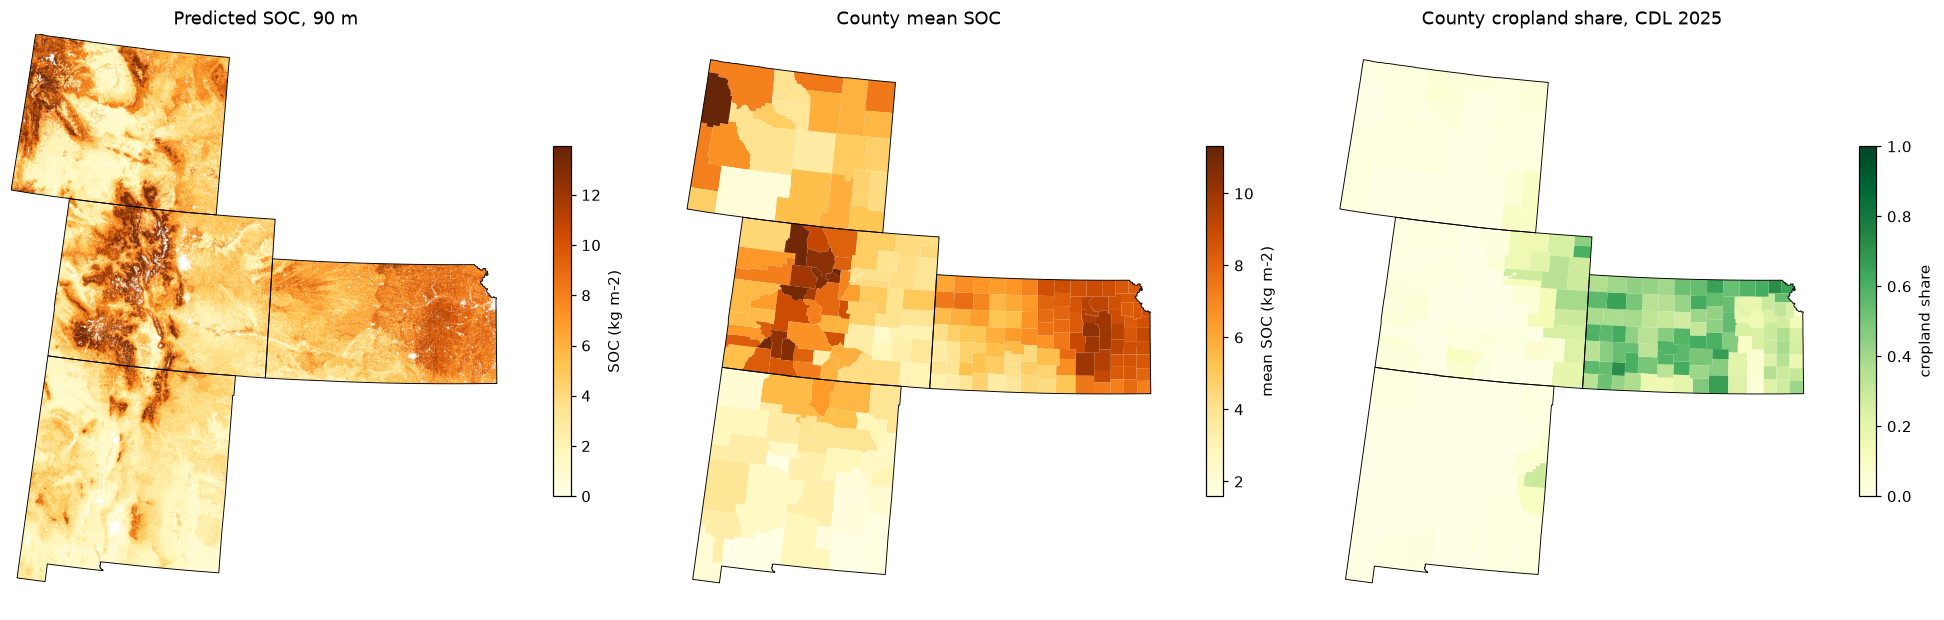

In [7]:
fig, ax = plt.subplots(1, 3, figsize=(18, 5.6))  # three maps
q = dd.quicklook(soc_map, 10)  # every 10th pixel
im = ax[0].imshow(q, cmap="YlOrBr", vmin=0, vmax=np.nanpercentile(q, 98), extent=dd.extent(q))  # pixel map
plt.colorbar(im, ax=ax[0], shrink=0.6, label="SOC (kg m-2)"); ax[0].set_title("Predicted SOC, 90 m")  # labels
counties.plot("soc_mean", ax=ax[1], cmap="YlOrBr", legend=True, legend_kwds={"shrink": 0.6, "label": "mean SOC (kg m-2)"})  # county SOC
counties.plot("crop_share", ax=ax[2], cmap="YlGn", vmin=0, vmax=1, legend=True, legend_kwds={"shrink": 0.6, "label": "cropland share"})  # cropland
ax[1].set_title("County mean SOC"); ax[2].set_title("County cropland share, CDL 2025")  # titles
for a in ax:  # all maps
    dd.gp_states().boundary.plot(ax=a, color="k", lw=0.6); a.set_axis_off()  # states
plt.tight_layout(); plt.show()  # draw

## Stage 6: spatial patterns

Is county SOC spatially clustered, and does cropland share explain it once climate is accounted
for? Queen weights, Moran's I, LISA and G* (notebook 06) on the county means, then a simple
regression of county SOC on cropland share, precipitation and temperature.

In [8]:
t0 = time.perf_counter()  # start
w = pdist.analysis.weights(counties, "queen")  # queen contiguity
mi = pdist.analysis.morans_i(counties.soc_mean.values, w, permutations=999, seed=0, compute=gpu)  # global
lisa = pdist.analysis.local_morans(counties.soc_mean.values, w, permutations=999, seed=0, compute=gpu)  # local
gstar = pdist.analysis.getis_ord_local(counties.soc_mean.values, w)  # hot spots
counties["lisa_q"] = np.where(lisa.p_sim < 0.05, lisa.q.map({1: "HH", 2: "LH", 3: "LL", 4: "HL"}), "ns")  # significant quadrants
counties["gstar_z"] = gstar.Zs.values  # z-scores
Z = np.column_stack([np.ones(len(counties)), counties.crop_share, counties.preci_mean / 100, counties.temp_mean])  # design matrix
beta, *_ = np.linalg.lstsq(Z, counties.soc_mean.values, rcond=None)  # least squares
fit = Z @ beta  # fitted values
resid = counties.soc_mean.values - fit  # residuals
mi_res = pdist.analysis.morans_i(resid, w, permutations=999, seed=0)  # are residuals still clustered?
budget["6 spatial statistics and regression"] = time.perf_counter() - t0  # time
print(f"Moran's I of county SOC {mi.statistic:.2f} (p_sim {mi.p_sim:.3f}); LISA clusters: {counties.lisa_q.value_counts().to_dict()}")  # global and local
print("SOC = {:.2f} + {:.2f} crop share + {:.2f} per 100 mm precipitation + {:.2f} per degree C; R2 {:.2f}".format(*beta, r2_score(counties.soc_mean, fit)))  # regression
print(f"Moran's I of the residuals {mi_res.statistic:.2f} (p_sim {mi_res.p_sim:.3f})")  # remaining clustering

Moran's I of county SOC 0.78 (p_sim 0.001); LISA clusters: {'ns': 115, 'HH': 59, 'LL': 51}
SOC = 4.27 + 1.32 crop share + 0.93 per 100 mm precipitation + -0.39 per degree C; R2 0.84
Moran's I of the residuals 0.61 (p_sim 0.001)


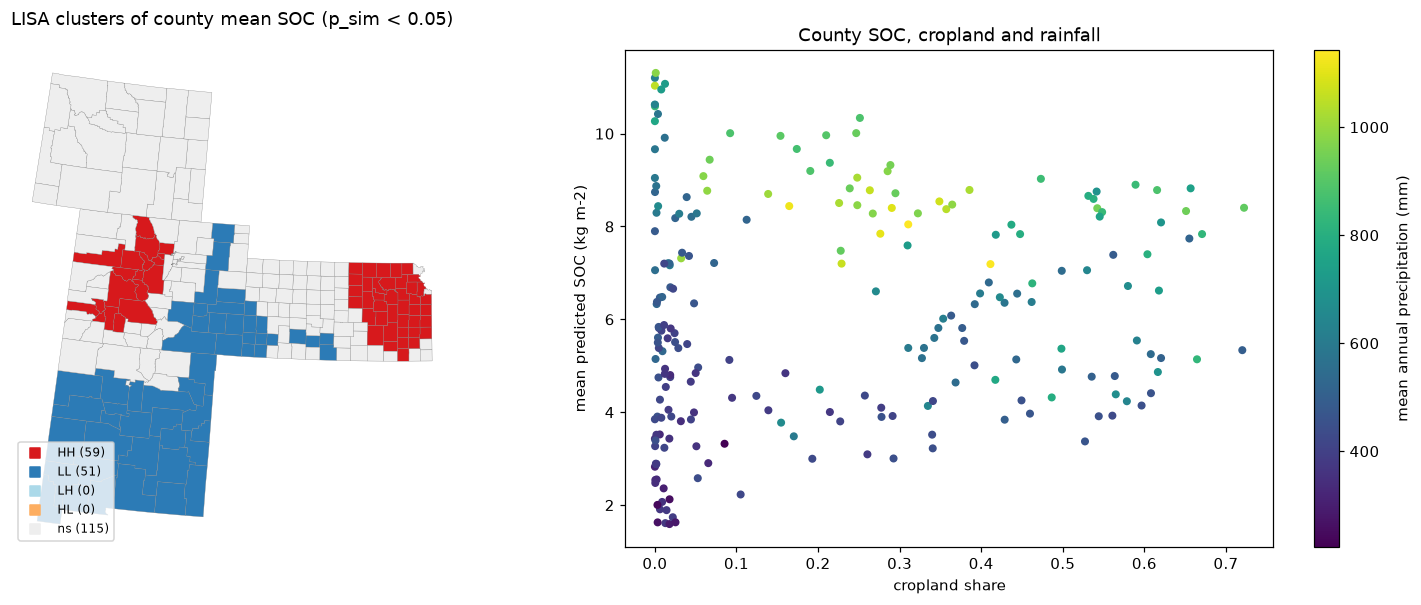

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(15, 5.6))  # two panels
colors = {"HH": "#d7191c", "LL": "#2c7bb6", "LH": "#abd9e9", "HL": "#fdae61", "ns": "#eeeeee"}  # quadrant colours
counties.plot(color=counties.lisa_q.map(colors), ax=ax[0], edgecolor="grey", linewidth=0.2)  # LISA map
for k, v in colors.items():  # legend entries
    ax[0].scatter([], [], color=v, label=f"{k} ({(counties.lisa_q == k).sum()})", marker="s")  # proxy artists
ax[0].legend(fontsize=8, loc="lower left"); ax[0].set_title("LISA clusters of county mean SOC (p_sim < 0.05)"); ax[0].set_axis_off()  # labels
sc = ax[1].scatter(counties.crop_share, counties.soc_mean, c=counties.preci_mean, cmap="viridis", s=18)  # SOC against cropland
plt.colorbar(sc, ax=ax[1], label="mean annual precipitation (mm)")  # colour scale
ax[1].set_xlabel("cropland share"); ax[1].set_ylabel("mean predicted SOC (kg m-2)"); ax[1].set_title("County SOC, cropland and rainfall")  # labels
plt.tight_layout(); plt.show()  # draw

County SOC is strongly clustered (Moran's I about 0.8): a high-high cluster in the wetter east of
Kansas and another in the Colorado mountains, low-low clusters across New Mexico and the dry
plains of south-eastern Colorado. Precipitation and temperature explain most of the county
differences. The regression gives cropland share a **positive** coefficient, which seems to
contradict the expectation that cultivation lowers SOC. It does not: in the Great Plains, cropland
is concentrated on the deeper, wetter soils of central and eastern Kansas, and the regression
picks up where crops are grown, not what cultivation does to a given soil. The scatter shows it:
at the same rainfall, cropland and SOC are hardly related. A county regression cannot separate
the two; answering the causal question needs paired comparisons of cultivated and uncultivated
soils, or the causal methods of chapter 03. The residuals are still clustered, so a spatial
regression model (chapter 05) would be the next step.

## Outputs and the time budget

In [10]:
keep = ["FIPS", "county", "state", "mapped_km2", "crop_km2", "wheat_km2", "corn_km2", "crop_share", "soc_mean", "soc_Tg",  # columns
        "ndvi_mean", "preci_mean", "temp_mean", "slope_mean", "lisa_q", "gstar_z", "geometry"]  # to keep
counties[keep].to_parquet(CAP / "counties_soc_cropland.parquet")  # GeoParquet for GIS and later chapters
print("wrote", CAP / "counties_soc_cropland.parquet", "and", CAP / "soc_map_cog.tif")  # outputs
tb = pd.Series(budget, name="seconds").to_frame()  # time budget
tb["share %"] = 100 * tb.seconds / tb.seconds.sum()  # shares
print(f"total {tb.seconds.sum() / 60:.1f} minutes")  # total
tb.round(1)  # table

wrote outputs/capstone/counties_soc_cropland.parquet and outputs/capstone/soc_map_cog.tif
total 7.0 minutes


,seconds,share %
1 cropland by county (21 billion pixels),384.6,91.3
2 training table,6.6,1.6
3 model and spatial cross-validation,1.7,0.4
4a predict 262 million pixels,10.7,2.5
4b write the map as a COG,11.4,2.7
5 county zonal statistics (5 rasters),5.9,1.4
6 spatial statistics and regression,0.1,0.0


In [11]:
top = counties.nlargest(10, "soc_Tg")[["county", "state", "soc_mean", "soc_Tg", "crop_share"]]  # the largest SOC stocks
print(f"total predicted SOC stock in the 225 counties: {counties.soc_Tg.sum() / 1000:.2f} Pg")  # total
top.round(2)  # table

total predicted SOC stock in the 225 counties: 5.40 Pg


,county,state,soc_mean,soc_Tg,crop_share
71,Park County,WY,7.16,129.33,0.02
146,Teton County,WY,11.31,123.49,0.00
136,Carbon County,WY,5.38,111.04,0.00
129,Fremont County,WY,4.05,97.19,0.02
114,Sublette County,WY,6.69,85.48,0.02
177,Rio Arriba County,NM,5.50,83.91,0.00
90,Lincoln County,WY,7.20,76.35,0.02
161,Gunnison County,CO,8.87,74.91,0.00
138,Campbell County,WY,5.80,72.27,0.02
152,Catron County,NM,3.85,69.00,0.00


## Summary and exercises

- One pipeline joined every part of the chapter: an out-of-core pass over 21 billion CDL pixels,
  aligned covariate stacks, a spatially validated model, a 262 million pixel prediction, zonal
  statistics on CPU and GPU, and spatial statistics of the county table.
- Reading and decompressing the 10 m CDL dominated the time budget; that stage is I/O-bound and
  stays on the CPU, while the GPU took over the prediction and the zonal partial sums.
- County SOC was strongly clustered: high in the wetter east and the mountains, low on the warm,
  dry southern plains. A regression on cropland share, precipitation and temperature explained
  most of it (R2 about 0.8). Its positive cropland coefficient reflects where crops are grown, not
  an effect of cultivation, and its residuals remained clustered, so a spatial model (chapter 05)
  would be the next step.
- The results are analysis-ready: a county GeoParquet file and a COG of the SOC map.

**Exercises**

1. Run the whole notebook with `gpu = "cpu"` and compare the time budget stage by stage.
2. Replace cropland share with wheat share and corn share in the regression. Which crop is
   associated with lower SOC after accounting for climate?
3. Add the prediction uncertainty: fit 10 models on bootstrap samples, predict the map with each,
   and compute the county mean of the standard deviation.
4. Extend the cropland stage to the whole of Nebraska and South Dakota (the CDL is national) and
   compare their cropland shares with Kansas.

### Option B for further work

The outline of this chapter also proposed a Bangladesh flood exposure capstone: Microsoft building
footprints of Bangladesh (from the same Planetary Computer collection as the Kansas buildings),
the Sentinel-1 char land flood maps of the remote sensing capstone, a partitioned spatial join of
buildings to flooded areas, zonal counts per upazila, HDBSCAN settlement clusters and network
distance to the nearest road. Every step uses functions shown in notebooks 02 to 07.